# Calculative Foundation: Linear Algebra on Student Performance Data




## Goal
A research institute shared the scores of students in 5 subjects. In this notebook we use **Linear Algebra** to understand this data.

We will cover:
- **Part A:** Vectors (norms, dot product, angle, cross product, projection)
- **Part B:** Matrices (addition, multiplication, transpose, inverse, determinant)
- **Part C:** Linear transformations and geometry (line, plane, hyperplane)
- **Part D:** Eigenvalues and eigenvectors of the covariance matrix


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D plots
import os

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 100
os.makedirs("images", exist_ok=True)

df = pd.read_csv("data/student_scores.csv")
subjects = ["Maths", "Physics", "Chemistry", "English", "Computer"]
X = df[subjects].to_numpy(dtype=float)   # students x subjects matrix

print("Data shape (students, subjects):", X.shape)
df.head()

Data shape (students, subjects): (30, 5)


,Student_ID,Maths,Physics,Chemistry,English,Computer
0,S01,73,71,60,70,92
1,S02,54,55,56,61,62
2,S03,74,70,70,65,74
3,S04,76,73,77,71,82
4,S05,55,39,52,62,60


---
# Part A: Vector and Matrix Fundamentals

## A1. Each student is a vector
Each student has 5 scores, so each student is a **vector in 5 dimensions**:

`student = [Maths, Physics, Chemistry, English, Computer]`

In [2]:
s1 = X[0]   # Student S01
s2 = X[1]   # Student S02
print("Student S01 vector:", s1)
print("Student S02 vector:", s2)

Student S01 vector: [73. 71. 60. 70. 92.]
Student S02 vector: [54. 55. 56. 61. 62.]


## A2. Norm-1 and Norm-2
- **Norm-1 (L1):** sum of absolute values. It is the total marks of a student.  
  `||v||1 = |v1| + |v2| + ... + |vn|`
- **Norm-2 (L2):** the length of the vector.  
  `||v||2 = sqrt(v1^2 + v2^2 + ... + vn^2)`

Student  Norm-1 (manual)  Norm-2 (manual)  Norm-1 (numpy)  Norm-2 (numpy)
    S01            366.0           165.33           366.0          165.33
    S02            288.0           129.00           288.0          129.00
    S03            353.0           158.04           353.0          158.04
    S04            379.0           169.70           379.0          169.70
    S05            268.0           121.22           268.0          121.22
    S06            313.0           142.16           313.0          142.16
    S07            342.0           153.30           342.0          153.30
    S08            303.0           136.36           303.0          136.36
    S09            323.0           144.65           323.0          144.65
    S10            304.0           137.31           304.0          137.31


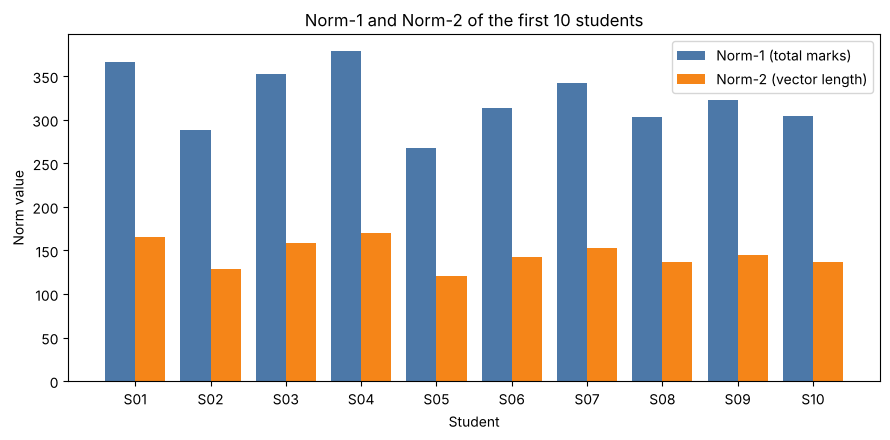

Interpretation: Among the first 10 students, S04 has the highest Norm-1, so this student has the highest total marks.


In [3]:
def norm1(v):
    return np.sum(np.abs(v))

def norm2(v):
    return np.sqrt(np.sum(v ** 2))

rows = []
for i in range(10):
    rows.append([df["Student_ID"][i], norm1(X[i]), norm2(X[i]),
                 np.linalg.norm(X[i], 1), np.linalg.norm(X[i], 2)])
norm_table = pd.DataFrame(rows, columns=["Student", "Norm-1 (manual)", "Norm-2 (manual)",
                                          "Norm-1 (numpy)", "Norm-2 (numpy)"])
print(norm_table.round(2).to_string(index=False))

# Chart
fig, ax = plt.subplots(figsize=(9, 4.5))
idx = np.arange(10)
ax.bar(idx - 0.2, norm_table["Norm-1 (manual)"], 0.4, label="Norm-1 (total marks)", color="#4C78A8")
ax.bar(idx + 0.2, norm_table["Norm-2 (manual)"], 0.4, label="Norm-2 (vector length)", color="#F58518")
ax.set_xticks(idx)
ax.set_xticklabels(norm_table["Student"])
ax.set_xlabel("Student")
ax.set_ylabel("Norm value")
ax.set_title("Norm-1 and Norm-2 of the first 10 students")
ax.legend()
plt.tight_layout()
plt.savefig("images/norms_bar.png")
plt.show()

best = norm_table.loc[norm_table["Norm-1 (manual)"].idxmax(), "Student"]
print(f"Interpretation: Among the first 10 students, {best} has the highest Norm-1, "
      f"so this student has the highest total marks.")

**Interpretation:** Norm-1 tells us the total marks. Norm-2 tells us the overall size of the score vector. A student with higher scores in all subjects has bigger norms.

## A3. Dot product and angle between two students
- **Dot product:** `a . b = a1*b1 + a2*b2 + ... + an*bn`
- **Angle:** `cos(theta) = (a . b) / (||a|| * ||b||)`

If the angle is small, the two students have a **similar score pattern**.

In [4]:
dot = np.dot(s1, s2)
cos_theta = dot / (norm2(s1) * norm2(s2))
angle_deg = np.degrees(np.arccos(cos_theta))

print("Dot product of S01 and S02 :", dot)
print("Cosine of the angle        :", round(cos_theta, 4))
print("Angle between S01 and S02  :", round(angle_deg, 2), "degrees")
print()
print(f"Interpretation: The angle is only {angle_deg:.2f} degrees, so S01 and S02 have a very similar score pattern.")
print("(All scores are positive, so angles between students are usually small. Compare angles of different pairs to see who is more alike.)")

Dot product of S01 and S02 : 21181.0
Cosine of the angle        : 0.9931
Angle between S01 and S02  : 6.74 degrees

Interpretation: The angle is only 6.74 degrees, so S01 and S02 have a very similar score pattern.
(All scores are positive, so angles between students are usually small. Compare angles of different pairs to see who is more alike.)


## A4. Cross product (3D subjects)
The cross product works only in **3D**. We select 3 subjects: **Maths, Physics, Chemistry**.

`a x b` gives a new vector that is **perpendicular** to both `a` and `b`.  
Its length is the **area of the parallelogram** made by the two vectors.

a (S01) = [73. 71. 60.]
b (S02) = [54. 55. 56.]
a x b   = [ 676. -848.  181.]
Area of parallelogram = 1099.47
Check: (a x b) . a = 0.0 and (a x b) . b = 0.0

Interpretation: Both dot products are 0, so the cross product is perpendicular to both score vectors.


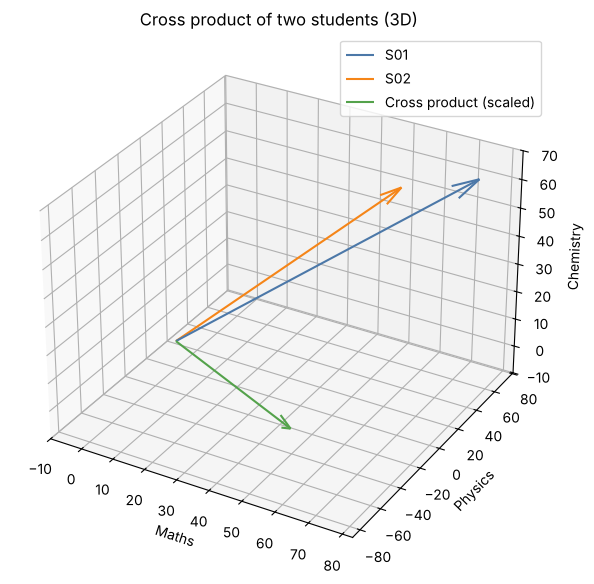

In [5]:
a = X[0, :3]   # S01: Maths, Physics, Chemistry
b = X[1, :3]   # S02: Maths, Physics, Chemistry
cross = np.cross(a, b)

print("a (S01) =", a)
print("b (S02) =", b)
print("a x b   =", cross)
print("Area of parallelogram =", round(np.linalg.norm(cross), 2))
print("Check: (a x b) . a =", round(np.dot(cross, a), 6), "and (a x b) . b =", round(np.dot(cross, b), 6))
print()
print("Interpretation: Both dot products are 0, so the cross product is perpendicular to both score vectors.")

# 3D chart
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
scale = 100 / np.linalg.norm(cross)   # shrink the cross vector so it fits on the chart
ax.quiver(0, 0, 0, *a, color="#4C78A8", label="S01", arrow_length_ratio=0.08)
ax.quiver(0, 0, 0, *b, color="#F58518", label="S02", arrow_length_ratio=0.08)
ax.quiver(0, 0, 0, *(cross * scale), color="#54A24B", label="Cross product (scaled)", arrow_length_ratio=0.08)
pts_all = np.array([[0, 0, 0], a, b, cross * scale])
lo, hi = pts_all.min(axis=0) - 10, pts_all.max(axis=0) + 10
ax.set_xlim(lo[0], hi[0])
ax.set_ylim(lo[1], hi[1])
ax.set_zlim(lo[2], hi[2])
ax.set_xlabel("Maths")
ax.set_ylabel("Physics")
ax.set_zlabel("Chemistry")
ax.set_title("Cross product of two students (3D)")
ax.legend()
plt.tight_layout()
plt.savefig("images/cross_product_3d.png")
plt.show()

## A5. Projection of one vector onto another
Projection of `a` onto `b`:

`proj_b(a) = ((a . b) / (b . b)) * b`

It shows how much of student `a`'s score pattern lies **in the direction** of student `b`.  
For the chart we use 2 subjects (Maths and Physics) so that we can draw it on a flat page. We pick the two students with the biggest angle, so the picture is clear.

Projection of S01 on S02 (5D): [68.728 70.001 71.274 77.637 78.91 ]
Scalar projection (length)   : 164.19
Length of S01                : 165.33
Chart students: S25 [55. 62.] and S06 [65. 46.]


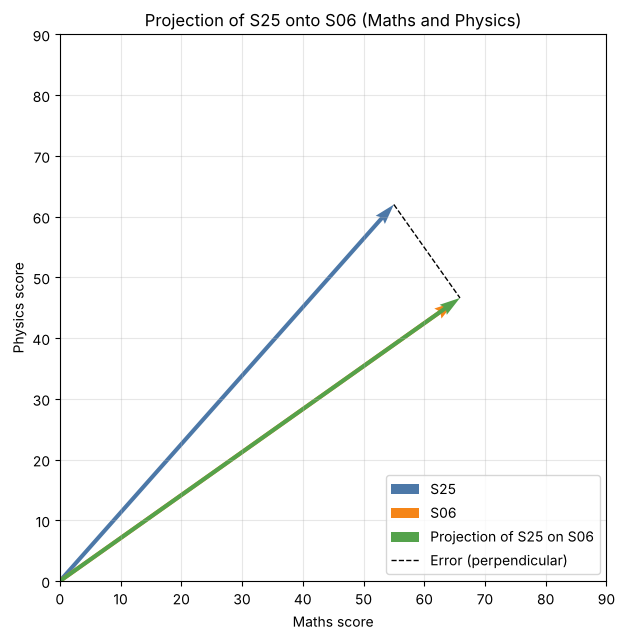

Interpretation: The green arrow is the part of S25 that points in the same direction as S06.
The dashed line is the leftover part, and it is perpendicular to S06. Check (error . S06) = -0.0


In [6]:
# Full 5D projection
proj5 = (np.dot(s1, s2) / np.dot(s2, s2)) * s2
scalar_proj = np.dot(s1, s2) / norm2(s2)
print("Projection of S01 on S02 (5D):", proj5)
print("Scalar projection (length)   :", round(scalar_proj, 2))
print("Length of S01                :", round(norm2(s1), 2))

# 2D projection for the chart (Maths, Physics)
# S01 and S02 point almost in the same direction, so the chart would look crowded.
# For a clear picture we pick the two students whose (Maths, Physics) vectors have the biggest angle.
ratio = X[:, 1] / X[:, 0]                 # Physics / Maths
i_a, i_b = np.argmax(ratio), np.argmin(ratio)
name_a, name_b = df["Student_ID"][i_a], df["Student_ID"][i_b]
p = X[i_a, :2]
q = X[i_b, :2]
proj2 = (np.dot(p, q) / np.dot(q, q)) * q
error = p - proj2
print(f"Chart students: {name_a} {p} and {name_b} {q}")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.quiver(0, 0, *p, angles="xy", scale_units="xy", scale=1, color="#4C78A8", label=name_a)
ax.quiver(0, 0, *q, angles="xy", scale_units="xy", scale=1, color="#F58518", label=name_b)
ax.quiver(0, 0, *proj2, angles="xy", scale_units="xy", scale=1, color="#54A24B", label=f"Projection of {name_a} on {name_b}")
ax.plot([p[0], proj2[0]], [p[1], proj2[1]], "k--", linewidth=1, label="Error (perpendicular)")
ax.set_xlim(0, 90)
ax.set_ylim(0, 90)
ax.set_xlabel("Maths score")
ax.set_ylabel("Physics score")
ax.set_title(f"Projection of {name_a} onto {name_b} (Maths and Physics)")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/vector_projection.png")
plt.show()

print(f"Interpretation: The green arrow is the part of {name_a} that points in the same direction as {name_b}.")
print(f"The dashed line is the leftover part, and it is perpendicular to {name_b}. Check (error . {name_b}) =", round(np.dot(error, q), 6))

---
# Part B: Matrix Operations

## B1. Students x Subjects matrix
We stack all student vectors to make one matrix **X** of size 30 x 5 (30 students, 5 subjects).

In [7]:
print("Shape of X:", X.shape)
print("First 5 rows of X:")
print(X[:5])

Shape of X: (30, 5)
First 5 rows of X:
[[73. 71. 60. 70. 92.]
 [54. 55. 56. 61. 62.]
 [74. 70. 70. 65. 74.]
 [76. 73. 77. 71. 82.]
 [55. 39. 52. 62. 60.]]


## B2. Matrix addition
We add a **bonus marks matrix** to the first 5 students. Both matrices must have the **same shape** to be added.

In [8]:
A = X[:5]                               # 5 x 5 scores
bonus = np.array([[2, 0, 0, 1, 3],
                  [0, 2, 1, 0, 2],
                  [1, 1, 0, 0, 0],
                  [3, 0, 2, 1, 0],
                  [0, 4, 0, 2, 1]], dtype=float)
new_scores = A + bonus
print("Original scores:\n", A)
print("\nBonus marks:\n", bonus)
print("\nA + Bonus:\n", new_scores)

Original scores:
 [[73. 71. 60. 70. 92.]
 [54. 55. 56. 61. 62.]
 [74. 70. 70. 65. 74.]
 [76. 73. 77. 71. 82.]
 [55. 39. 52. 62. 60.]]

Bonus marks:
 [[2. 0. 0. 1. 3.]
 [0. 2. 1. 0. 2.]
 [1. 1. 0. 0. 0.]
 [3. 0. 2. 1. 0.]
 [0. 4. 0. 2. 1.]]

A + Bonus:
 [[75. 71. 60. 71. 95.]
 [54. 57. 57. 61. 64.]
 [75. 71. 70. 65. 74.]
 [79. 73. 79. 72. 82.]
 [55. 43. 52. 64. 61.]]


## B3. Matrix multiplication
Two useful examples:

1. **Weighted final score:** `X @ w`. Here `w` is a 5 x 1 weight vector. The result is a 30 x 1 vector (one final score per student).
2. **Gram matrix:** `X^T @ X`. The result is a 5 x 5 matrix that compares subjects with each other.

For multiplication, the **inner sizes must match**: (m x n) @ (n x p) gives (m x p).

In [9]:
# 1) Weighted final score
w = np.array([0.30, 0.25, 0.20, 0.10, 0.15])   # weights add up to 1
final_score = X @ w
print("Weights:", w, "| sum =", w.sum())
print("Shape: X", X.shape, "@ w", w.shape, "->", final_score.shape)
print("Final scores of first 5 students:", final_score[:5].round(2))

# 2) Gram matrix X^T X
gram = X.T @ X
print("\nShape of X^T X:", gram.shape)
print(pd.DataFrame(gram, index=subjects, columns=subjects).round(0))

Weights: [0.3  0.25 0.2  0.1  0.15] | sum = 1.0
Shape: X (30, 5) @ w (5,) -> (30,)
Final scores of first 5 students: [72.45 56.55 71.3  75.85 51.85]

Shape of X^T X: (5, 5)
              Maths   Physics  Chemistry   English  Computer
Maths      141410.0  132391.0   130403.0  142979.0  150973.0
Physics    132391.0  125052.0   122336.0  133967.0  141285.0
Chemistry  130403.0  122336.0   121400.0  132353.0  139221.0
English    142979.0  133967.0   132353.0  146279.0  152782.0
Computer   150973.0  141285.0   139221.0  152782.0  162362.0


## B4. Transpose

In [10]:
Xt = X.T
print("Shape of X  :", X.shape)
print("Shape of X^T:", Xt.shape)
print("First 3 columns of X^T (first 3 students):")
print(Xt[:, :3])
print("\nCheck (X^T)^T equals X:", np.array_equal(Xt.T, X))

Shape of X  : (30, 5)
Shape of X^T: (5, 30)
First 3 columns of X^T (first 3 students):
[[73. 54. 74.]
 [71. 55. 70.]
 [60. 56. 70.]
 [70. 61. 65.]
 [92. 62. 74.]]

Check (X^T)^T equals X: True


## B5. Determinant and Inverse
- The **determinant** is a single number for a **square** matrix. If it is **0**, the matrix has **no inverse**.
- The **inverse** `A^-1` satisfies `A @ A^-1 = I` (identity matrix).

`X` is 30 x 5, which is **not square**, so it has no determinant and no inverse. We use square matrices instead.

In [11]:
# X is not square
try:
    np.linalg.inv(X)
except np.linalg.LinAlgError as e:
    print("Inverse of X is not possible:", e)

# Example 1: small 3 x 3 matrix (first 3 students, first 3 subjects)
M = X[:3, :3]
det_M = np.linalg.det(M)
print("\n3 x 3 matrix M:\n", M)
print("Determinant of M:", round(det_M, 2))
if abs(det_M) > 1e-9:
    M_inv = np.linalg.inv(M)
    print("Inverse of M:\n", M_inv)
    print("M @ M_inv (should be identity):\n", (M @ M_inv).round(6))

# Example 2: covariance matrix (5 x 5)
cov = np.cov(X, rowvar=False)
det_cov = np.linalg.det(cov)
print("\nDeterminant of covariance matrix:", round(det_cov, 2))
cov_inv = np.linalg.inv(cov)
print("Check cov @ cov_inv = Identity:", np.allclose(cov @ cov_inv, np.eye(5)))
print("Rank of X:", np.linalg.matrix_rank(X))

Inverse of X is not possible: Last 2 dimensions of the array must be square

3 x 3 matrix M:
 [[73. 71. 60.]
 [54. 55. 56.]
 [74. 70. 70.]]
Determinant of M: 3334.0
Inverse of M:
 [[-0.021 -0.231  0.203]
 [ 0.109  0.201 -0.254]
 [-0.087  0.043  0.054]]
M @ M_inv (should be identity):
 [[ 1. -0.  0.]
 [ 0.  1. -0.]
 [ 0.  0.  1.]]

Determinant of covariance matrix: 72429214.03
Check cov @ cov_inv = Identity: True
Rank of X: 5


**Interpretation:** The determinant is not zero for these square matrices, so they are **invertible**. This means the subjects are not exact copies of each other. Every subject adds some new information.

---
# Part C: Linear Transformations and Geometry

## C1. Line, plane and hyperplane in our dataset
| Number of subjects (dimensions) | Shape that separates or fits the data | Example in our data |
|---|---|---|
| 2 (2D) | **Line** | Physics = a * Maths + b |
| 3 (3D) | **Plane** | Chemistry = a * Maths + b * Physics + c |
| n (higher) | **Hyperplane** (has n-1 dimensions) | Computer = w1*Maths + w2*Physics + w3*Chemistry + w4*English + b |

- A **line** is a flat 1D shape inside 2D space.
- A **plane** is a flat 2D shape inside 3D space.
- A **hyperplane** is a flat (n-1)D shape inside n-D space. We cannot draw it, but the math is the same.

In [12]:
# Line: Physics vs Maths
m, c = np.polyfit(df["Maths"], df["Physics"], 1)
print(f"LINE (2D):  Physics = {m:.3f} * Maths + {c:.3f}")

# Plane: Chemistry = a*Maths + b*Physics + c
A3 = np.column_stack([df["Maths"], df["Physics"], np.ones(len(df))])
coef3, *_ = np.linalg.lstsq(A3, df["Chemistry"], rcond=None)
print(f"PLANE (3D): Chemistry = {coef3[0]:.3f} * Maths {coef3[1]:+.3f} * Physics {coef3[2]:+.3f}")

# Hyperplane: Computer from the other 4 subjects
A5 = np.column_stack([df[["Maths", "Physics", "Chemistry", "English"]].to_numpy(), np.ones(len(df))])
coef5, *_ = np.linalg.lstsq(A5, df["Computer"], rcond=None)
print("HYPERPLANE (5D):")
print(f"  Computer = {coef5[0]:.3f}*Maths {coef5[1]:+.3f}*Physics {coef5[2]:+.3f}*Chemistry "
      f"{coef5[3]:+.3f}*English {coef5[4]:+.3f}")
print()
print("Interpretation: The Maths weight is close to 1 and the other weights are close to 0.")
print("So in this dataset, Computer score is mostly explained by Maths score.")

LINE (2D):  Physics = 0.918 * Maths + 1.238
PLANE (3D): Chemistry = 0.458 * Maths +0.218 * Physics +17.991
HYPERPLANE (5D):
  Computer = 1.023*Maths -0.043*Physics -0.048*Chemistry -0.062*English +13.261

Interpretation: The Maths weight is close to 1 and the other weights are close to 0.
So in this dataset, Computer score is mostly explained by Maths score.


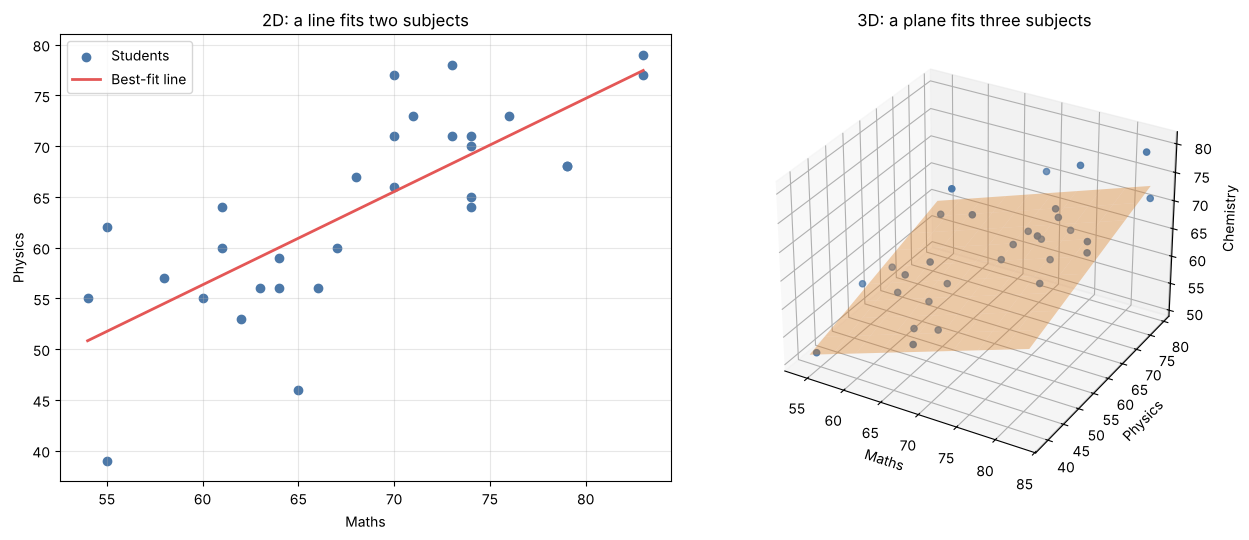

Interpretation: In 2D the data is described by a line, and in 3D by a plane.
With 5 subjects the same idea gives a hyperplane that we cannot draw, but we can still calculate it.


In [13]:
fig = plt.figure(figsize=(13, 5.5))

# Left: line in 2D
ax1 = fig.add_subplot(121)
ax1.scatter(df["Maths"], df["Physics"], color="#4C78A8", label="Students")
xs = np.linspace(df["Maths"].min(), df["Maths"].max(), 50)
ax1.plot(xs, m * xs + c, color="#E45756", linewidth=2, label="Best-fit line")
ax1.set_xlabel("Maths")
ax1.set_ylabel("Physics")
ax1.set_title("2D: a line fits two subjects")
ax1.legend()
ax1.grid(alpha=0.3)

# Right: plane in 3D
ax2 = fig.add_subplot(122, projection="3d")
ax2.scatter(df["Maths"], df["Physics"], df["Chemistry"], color="#4C78A8")
gx, gy = np.meshgrid(np.linspace(df["Maths"].min(), df["Maths"].max(), 10),
                     np.linspace(df["Physics"].min(), df["Physics"].max(), 10))
gz = coef3[0] * gx + coef3[1] * gy + coef3[2]
ax2.plot_surface(gx, gy, gz, alpha=0.35, color="#F58518")
ax2.set_xlabel("Maths")
ax2.set_ylabel("Physics")
ax2.set_zlabel("Chemistry")
ax2.set_title("3D: a plane fits three subjects")

plt.tight_layout()
plt.savefig("images/line_plane_fit.png")
plt.show()

print("Interpretation: In 2D the data is described by a line, and in 3D by a plane.")
print("With 5 subjects the same idea gives a hyperplane that we cannot draw, but we can still calculate it.")

## C2. Linear transformation
A matrix can **move, stretch, or rotate** every vector. This is called a **linear transformation**.

We take a 2D matrix `T` and apply it to the (Maths, Physics) points:  
`new_point = T @ old_point`

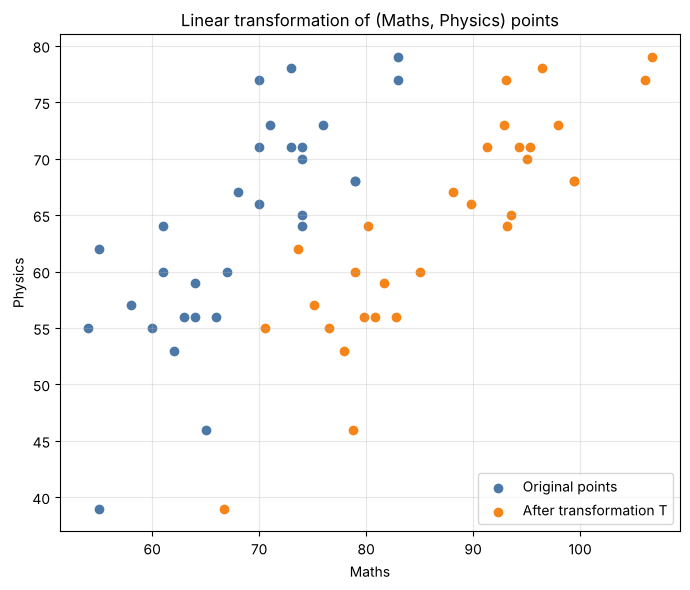

Transformation matrix T:
 [[1.  0.3]
 [0.  1. ]]
Interpretation: Every orange point is the matching blue point after it was moved sideways by T.


In [14]:
T = np.array([[1.0, 0.3],
              [0.0, 1.0]])    # shear: Maths gets extra weight from Physics
pts = X[:, :2].T               # 2 x 30
new_pts = T @ pts

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(pts[0], pts[1], color="#4C78A8", label="Original points")
ax.scatter(new_pts[0], new_pts[1], color="#F58518", label="After transformation T")
ax.set_xlabel("Maths")
ax.set_ylabel("Physics")
ax.set_title("Linear transformation of (Maths, Physics) points")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/linear_transformation.png")
plt.show()

print("Transformation matrix T:\n", T)
print("Interpretation: Every orange point is the matching blue point after it was moved sideways by T.")

---
# Part D: Eigenvalues and Decomposition

## D1. Covariance matrix
The **covariance matrix** shows how pairs of subjects move together. It is a 5 x 5 symmetric matrix.

           Maths  Physics  Chemistry  English  Computer
Maths      64.58    59.30      42.49    17.56     60.39
Physics    59.30    92.53      47.33    18.95     53.27
Chemistry  42.49    47.33      62.95    16.12     37.42
English    17.56    18.95      16.12    28.10     14.63
Computer   60.39    53.27      37.42    14.63     96.00


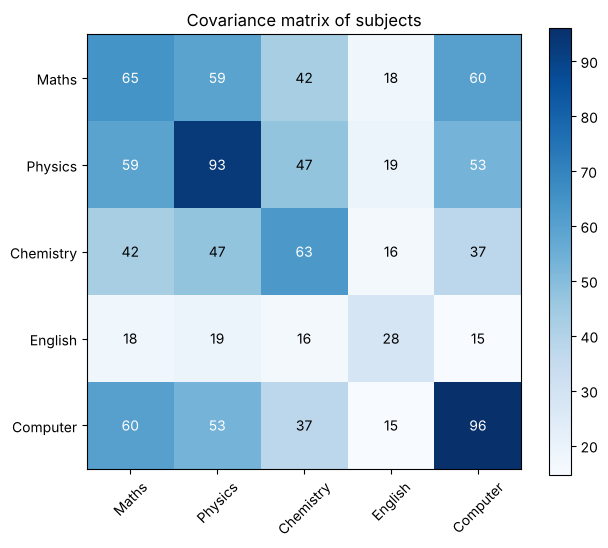

In [15]:
cov = np.cov(X, rowvar=False)
cov_df = pd.DataFrame(cov, index=subjects, columns=subjects)
print(cov_df.round(2))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cov, cmap="Blues")
ax.set_xticks(range(5))
ax.set_xticklabels(subjects, rotation=45)
ax.set_yticks(range(5))
ax.set_yticklabels(subjects)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cov[i, j]:.0f}", ha="center", va="center",
                color="white" if cov[i, j] > cov.max() / 2 else "black")
ax.set_title("Covariance matrix of subjects")
fig.colorbar(im)
plt.tight_layout()
plt.savefig("images/covariance_heatmap.png")
plt.show()

## D2. Eigenvalues and eigenvectors
For a matrix `C`, an **eigenvector** `v` is a direction that does not change when `C` is applied. It only gets scaled by the **eigenvalue** `lambda`:

`C v = lambda v`

For a covariance matrix:
- **Eigenvector** = a direction in the data (a new axis).
- **Eigenvalue** = how much **variance** the data has along that direction.

In [16]:
eigvals, eigvecs = np.linalg.eigh(cov)      # eigh is for symmetric matrices
order = np.argsort(eigvals)[::-1]           # sort from big to small
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

# Eigenvectors can point in two opposite directions. We pick the direction where the weights add up to a positive number.
for k in range(eigvecs.shape[1]):
    if eigvecs[:, k].sum() < 0:
        eigvecs[:, k] = -eigvecs[:, k]

explained = eigvals / eigvals.sum() * 100
cumulative = np.cumsum(explained)

print("Eigenvalues:", eigvals.round(2))
print("\nVariance explained (%):", explained.round(2))
print("Cumulative variance (%):", cumulative.round(2))
print("\nEigenvectors (each column is one eigenvector):")
print(pd.DataFrame(eigvecs, index=subjects, columns=[f"PC{i+1}" for i in range(5)]).round(3))

# Check C v = lambda v
v1 = eigvecs[:, 0]
print("\nCheck for the first eigenvector:")
print("C @ v1       =", (cov @ v1).round(3))
print("lambda1 * v1 =", (eigvals[0] * v1).round(3))
print("Same?", np.allclose(cov @ v1, eigvals[0] * v1))
print("Sum of eigenvalues =", round(eigvals.sum(), 2), "| Trace of covariance =", round(np.trace(cov), 2))

Eigenvalues: [237.47  45.63  28.49  21.81  10.76]

Variance explained (%): [69.   13.26  8.28  6.34  3.13]
Cumulative variance (%): [ 69.    82.26  90.54  96.87 100.  ]

Eigenvectors (each column is one eigenvector):
             PC1    PC2    PC3    PC4    PC5
Maths      0.487 -0.057 -0.007  0.050 -0.870
Physics    0.545  0.442 -0.654 -0.046  0.278
Chemistry  0.395  0.427  0.714 -0.351  0.168
English    0.158  0.173  0.238  0.934  0.128
Computer   0.534 -0.767  0.074 -0.014  0.347

Check for the first eigenvector:
C @ v1       = [115.554 129.426  93.877  37.491 126.767]
lambda1 * v1 = [115.554 129.426  93.877  37.491 126.767]
Same? True
Sum of eigenvalues = 344.16 | Trace of covariance = 344.16


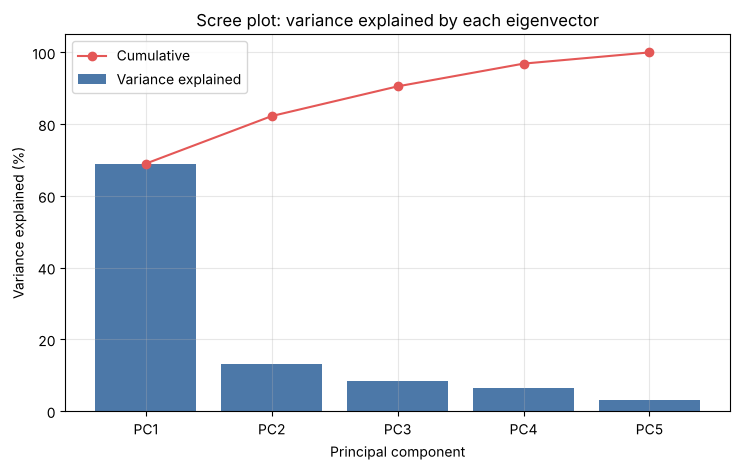

Interpretation: The first eigenvector (PC1) alone explains 69.0% of the total variance.
PC1 and PC2 together explain 82.3%.
PC1 has all positive weights, so it shows overall academic strength: a student who is good in one subject is usually good in the others.


In [17]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.bar(range(1, 6), explained, color="#4C78A8", label="Variance explained")
ax.plot(range(1, 6), cumulative, "o-", color="#E45756", label="Cumulative")
ax.set_xticks(range(1, 6))
ax.set_xticklabels([f"PC{i}" for i in range(1, 6)])
ax.set_xlabel("Principal component")
ax.set_ylabel("Variance explained (%)")
ax.set_title("Scree plot: variance explained by each eigenvector")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/scree_plot.png")
plt.show()

print(f"Interpretation: The first eigenvector (PC1) alone explains {explained[0]:.1f}% of the total variance.")
print(f"PC1 and PC2 together explain {cumulative[1]:.1f}%.")
print("PC1 has all positive weights, so it shows overall academic strength: a student who is good in one subject is usually good in the others.")

## D3. Using the eigenvectors: reducing 5 subjects to 2 dimensions
We project every student on the first two eigenvectors (PC1 and PC2). This is called **dimensionality reduction (PCA)**.

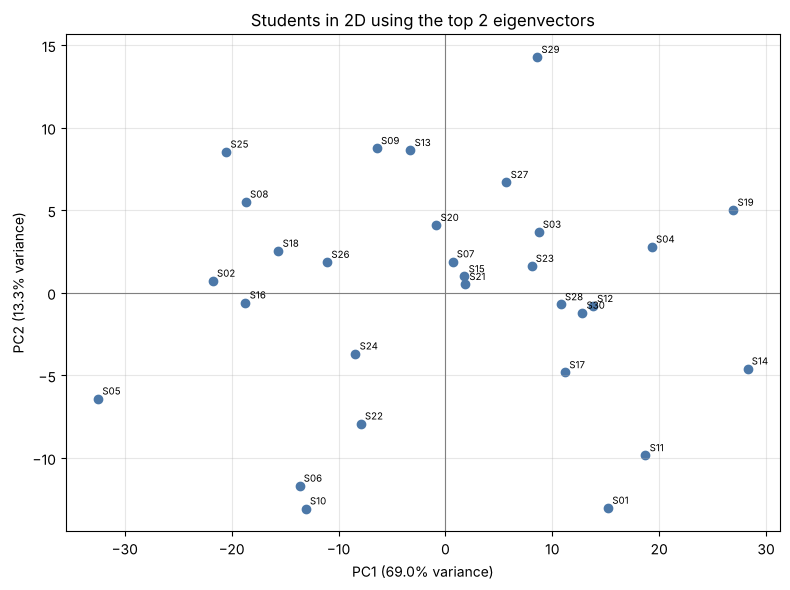

Interpretation: Students on the right side of the chart (for example S14) have high overall scores.
Students on the left side (for example S05) have low overall scores.


In [18]:
Xc = X - X.mean(axis=0)               # center the data
Z = Xc @ eigvecs[:, :2]               # 30 x 2

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Z[:, 0], Z[:, 1], color="#4C78A8")
for i, sid in enumerate(df["Student_ID"]):
    ax.annotate(sid, (Z[i, 0], Z[i, 1]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel(f"PC1 ({explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}% variance)")
ax.set_title("Students in 2D using the top 2 eigenvectors")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/pca_scatter.png")
plt.show()

top = df["Student_ID"][np.argmax(Z[:, 0])]
low = df["Student_ID"][np.argmin(Z[:, 0])]
print(f"Interpretation: Students on the right side of the chart (for example {top}) have high overall scores.")
print(f"Students on the left side (for example {low}) have low overall scores.")

---
# Conclusion
- **Vectors:** Each student is a 5D vector. Norms measure size, the dot product and angle measure similarity, the cross product gives a perpendicular direction (3D), and projection shows shared direction.
- **Matrices:** The students x subjects matrix lets us add, multiply, transpose and invert. Only square matrices have a determinant and inverse.
- **Geometry:** A line fits 2 subjects, a plane fits 3 subjects, and a hyperplane fits more than 3 subjects.
- **Eigenvalues:** The eigenvectors of the covariance matrix show the main directions of variation. The first one shows overall academic strength and explains most of the variance.